
## **Projet final fait par Aymane ICHOU et Jeathusan KUGATHAS**


L'objectif est de développer un modèle capable de classifier une image IRM du cerveau dans l'une des quatre catégories suivantes :
1. Glioma : gliome.
2. Meningioma : méningiome.
3. Pituitary : tumeur pituitaire.
4. No Tumor : absence de tumeur.

In [21]:
# Import des données

"""
import zipfile

print(os.listdir('/content'))

zip_path = "/content/brain_dataset.zip"
extract_path = "/content/brain_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset décompressé avec succès !")
"""

'\nimport zipfile\n\nprint(os.listdir(\'/content\'))\n\nzip_path = "/content/brain_dataset.zip"\nextract_path = "/content/brain_dataset"\n\nwith zipfile.ZipFile(zip_path, \'r\') as zip_ref:\n    zip_ref.extractall(extract_path)\n\nprint("Dataset décompressé avec succès !")\n'

In [22]:
import os
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:

train_dir = "/content/drive/MyDrive/brain_dataset/Training"
test_dir = "/content/drive/MyDrive/brain_dataset/Testing"

print("Classes d'entraînement :")
print(os.listdir(train_dir))

print("\nClasses de test :")
print(os.listdir(test_dir))

Classes d'entraînement :
['notumor', 'meningioma', 'glioma', 'pituitary']

Classes de test :
['pituitary', 'notumor', 'meningioma', 'glioma']


In [24]:
# On cherche à mieux connaitre notre dataset
# On regarde les classes et leurs répartitions
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

classes = sorted(os.listdir(train_dir))

print("Les différentes classes sont :")

for classe in classes:
    print("-", classe)
print("")

print("Nombre d'images par classe train:\n")

for classe in classes:
    chemin = os.path.join(train_dir, classe)

    nombre_images = len([
        f for f in os.listdir(chemin)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    print(f"{classe} : {nombre_images} images")

print("")
print("Nombre d'images de test par classe test:\n")

for classe in sorted(os.listdir(test_dir)):
    chemin = os.path.join(test_dir, classe)

    nombre_images = len([
        f for f in os.listdir(chemin)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    print(f"{classe} : {nombre_images} images")

Les différentes classes sont :
- glioma
- meningioma
- notumor
- pituitary

Nombre d'images par classe train:

glioma : 1400 images
meningioma : 1400 images
notumor : 1400 images
pituitary : 1400 images

Nombre d'images de test par classe test:

glioma : 400 images
meningioma : 400 images
notumor : 400 images
pituitary : 400 images


In [25]:
import os

print("train_dir =", train_dir)
for classe in classes:
    chemin = os.path.join(train_dir, classe)
    print(classe, "->", len(os.listdir(chemin)), "fichiers")

train_dir = /content/drive/MyDrive/brain_dataset/Training
glioma -> 1400 fichiers
meningioma -> 1400 fichiers
notumor -> 1400 fichiers
pituitary -> 1400 fichiers


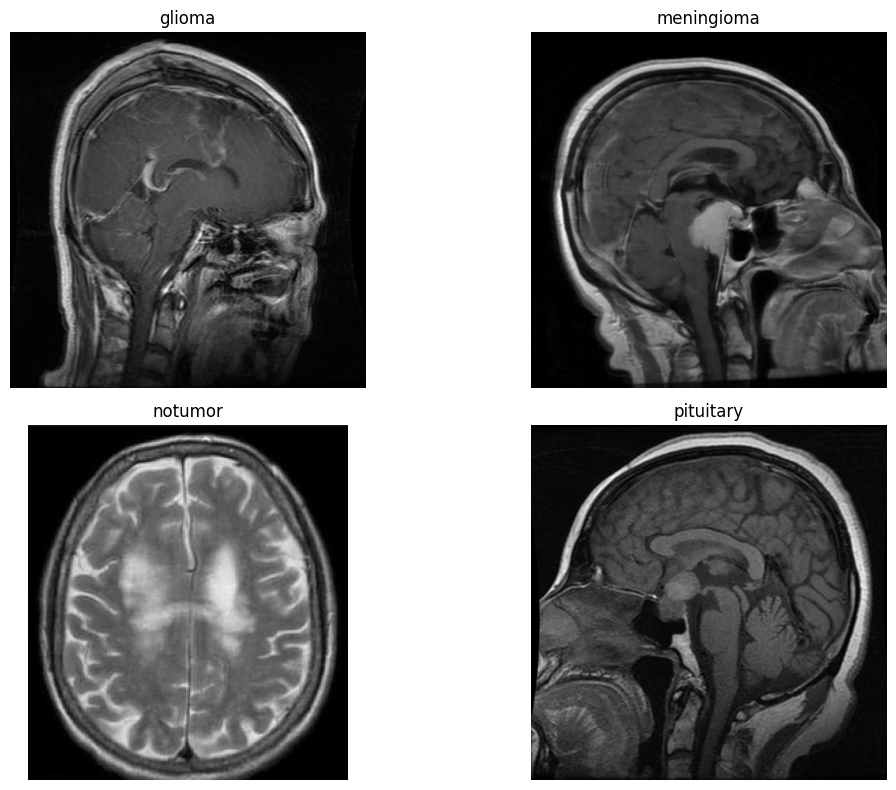

In [26]:
# On visualise quelques images
plt.figure(figsize=(12, 8))

for i, classe in enumerate(classes):

    chemin = os.path.join(train_dir, classe)

    images = os.listdir(chemin)

    image_path = os.path.join(chemin, images[0])

    img = Image.open(image_path)

    plt.subplot(2, 2, i+1)
    plt.imshow(img, cmap='gray')
    plt.title(classe)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [27]:
dimensions = []

for classe in classes:
    chemin = os.path.join(train_dir, classe)

    for fichier in os.listdir(chemin):

        if fichier.lower().endswith(('.jpg', '.jpeg', '.png')):

            image_path = os.path.join(chemin, fichier)

            img = Image.open(image_path)

            dimensions.append(img.size)

print("Nombre d'images analysées :", len(dimensions))
print("Quelques dimensions :", dimensions[:10])

largeurs = [d[0] for d in dimensions]
hauteurs = [d[1] for d in dimensions]

print("Largeur minimale :", min(largeurs))
print("Largeur maximale :", max(largeurs))

print("Hauteur minimale :", min(hauteurs))
print("Hauteur maximale :", max(hauteurs))

Nombre d'images analysées : 5600
Quelques dimensions : [(512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512)]
Largeur minimale : 150
Largeur maximale : 1375
Hauteur minimale : 168
Hauteur maximale : 1446


On remarque les images n'ont pas les mêmes tailles, c'est important de le savoir pour un CNN qui prend une taille d'entrée standard

## Prétraitement des données
Nous allons réaliser trois opérations :
1. Conversion des images en niveaux de gris (pour que toutes les images soient uniforme meme si c'est déjà le cas).
2. Redimensionnement en 128 × 128 pixels.
3. Normalisation des valeurs des pixels entre 0 et 1.

Pourquoi ces transformations ?
1. Pour les niveaux de gris, ça permet de réduire les informations redondantes des canaux RGB.

2. La taille 128 × 128 permet d'obtenir une taille fixe et réduire le coût de calcul.

3. et la normalisation	permet de faciliter la convergence du réseau pendant l'apprentissage.

In [28]:
# Prétraitement des données

from tensorflow.keras.preprocessing.image import ImageDataGenerator
IMG_SIZE = 128
BATCH_SIZE = 32

# Données train
train_datagen = ImageDataGenerator(
    rescale=1./255,  # Normalisation des valeurs des pixels
    validation_split=0.2 #réserve 20 % des images d'entraînement pour la validation.
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42
)

validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42
)

# Données test
test_datagen = ImageDataGenerator(
    rescale=1./255
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("Images d'entraînement :", train_generator.samples)
print("Images de validation :", validation_generator.samples)
print("Images de test :", test_generator.samples)

print("\nDimensions des images :", train_generator.image_shape)
print("\nClasses :", train_generator.class_indices)

Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.
Images d'entraînement : 4480
Images de validation : 1120
Images de test : 1600

Dimensions des images : (128, 128, 1)

Classes : {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


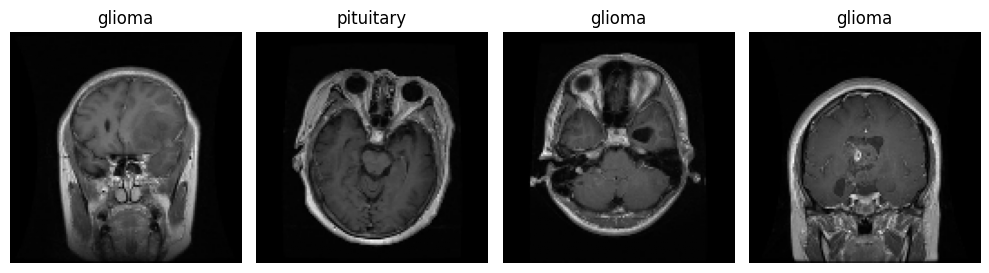

Valeur minimale : 0.0
Valeur maximale : 1.0


In [29]:
# On check quelques images apres le pre-traitement
images, labels = next(train_generator)

plt.figure(figsize=(10, 5))

for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(images[i].squeeze(), cmap='gray')
    plt.title(list(train_generator.class_indices.keys())[
        np.argmax(labels[i])
    ])
    plt.axis('off')

plt.tight_layout()
plt.show()

print("Valeur minimale :", images.min())
print("Valeur maximale :", images.max())

In [30]:
# Construction du modèle

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)


À quoi servent ces couches ?
- Conv2D : détecte les caractéristiques visuelles des IRM, comme les contours et les textures.
- MaxPooling2D : réduit progressivement la taille des images.
- BatchNormalization : aide à stabiliser et accélérer l’apprentissage.
- Flatten : transforme les caractéristiques en un vecteur.
- Dense : réalise la classification.
- Dropout : limite le surapprentissage (overfitting).

In [31]:
model = Sequential([

    # Bloc convolutif entrée
    Conv2D(32, (3, 3), activation='relu',
           padding='same', input_shape=(128, 128, 1)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Bloc convolutif 2
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Bloc convolutif 3
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Bloc convolutif 4
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Partie classification
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),

    # Couche de sortie : 4 classes
    Dense(4, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,585,348 (17.49 MB)

 Trainable params: 4,584,388 (17.49 MB)

 Non-trainable params: 960 (3.75 KB)

## Justification de l'architecture

Nombre de convolutions :
4 couches, cela permet d'extraire progressivement des caractéristiques de plus en plus complexes.

Nombre de filtres	:32, 64, 128, 256
Augmente la capacité du réseau à détecter des caractéristiques variées.

Taille des noyaux :	3 × 3
Permet de détecter des motifs locaux tout en limitant le nombre de paramètres.

Activation	ReLU : 	Introduit de la non-linéarité et facilite l'apprentissage.

Pooling	MaxPooling : 2 × 2	Réduit les dimensions spatiales et le coût de calcul.

Normalisation :	BatchNormalization qui sabilise l'apprentissage.

Couche Dense : 256 neurones
Combine les caractéristiques extraites pour effectuer la classification.

Dropout :	0,5
Désactive aléatoirement 50 % des neurones pendant l'entraînement afin de limiter le surapprentissage.

Sortie : 4 neurones Softmax
Produit une probabilité pour chacune des quatre classes du dataset.



In [32]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [33]:
# Callbacks
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

#EarlyStopping : arrête l'entraînement si les performances sur la validation ne s'améliorent plus.
#ReduceLROnPlateau : diminue le taux d'apprentissage lorsque le modèle ne progresse plus.

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

In [34]:
# Entrainement

history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 157ms/step - accuracy: 0.6228 - loss: 1.8654 - val_accuracy: 0.2500 - val_loss: 12.9910 - learning_rate: 0.0010
Epoch 2/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 134ms/step - accuracy: 0.7181 - loss: 0.7202 - val_accuracy: 0.2804 - val_loss: 6.2186 - learning_rate: 0.0010
Epoch 3/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 134ms/step - accuracy: 0.7634 - loss: 0.6266 - val_accuracy: 0.3295 - val_loss: 4.6721 - learning_rate: 0.0010
Epoch 4/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 131ms/step - accuracy: 0.7882 - loss: 0.5608 - val_accuracy: 0.7554 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 5/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - accuracy: 0.8080 - loss: 0.4955 - val_accuracy: 0.7563 - val_loss: 0.6168 - learning_rate: 0.0010
Epoch 6/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 127ms/step - accuracy: 0.8225 - loss: 0.4555 - val_accuracy: 0.8455 - val_loss: 0.4287 - learning_rate: 0.0010
Epoch 7/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 135ms/step - accuracy: 0.

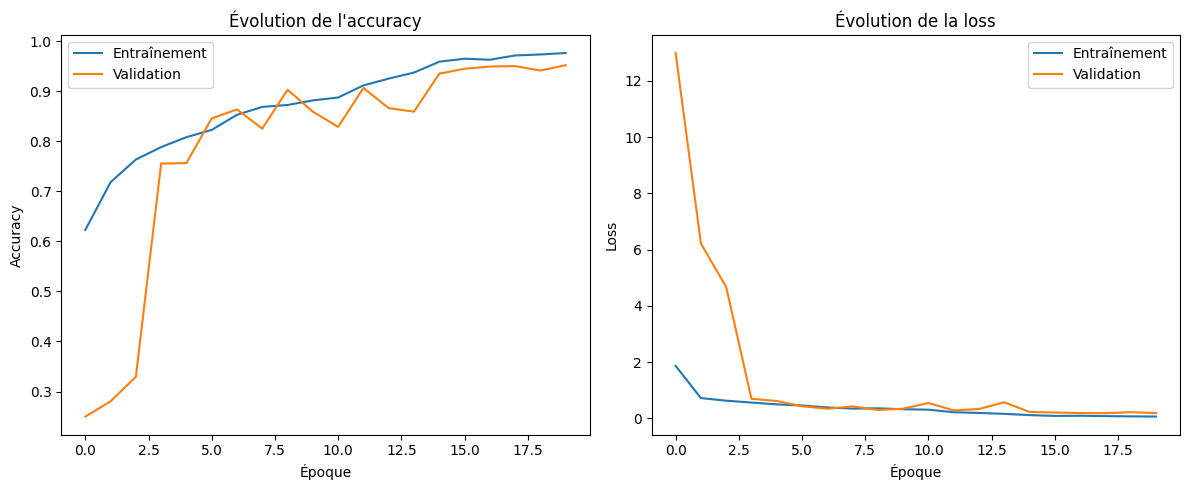

In [35]:
# Suivi des courbes d'accuracy et de loss

plt.figure(figsize=(12, 5))

# Courbe de l'accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Entraînement')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title("Évolution de l'accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()

# Courbe de la loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Entraînement')
plt.plot(history.history['val_loss'], label='Validation')
plt.title("Évolution de la loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Comment interpréter les courbes ?
- Si l'accuracy d'entraînement et celle de validation augmentent, le modèle apprend.
- Si les deux courbes de loss diminuent, le modèle réduit ses erreurs.
- Si l'accuracy d'entraînement continue d'augmenter alors que celle de validation stagne ou diminue, cela peut indiquer du surapprentissage.
- Si les performances restent faibles sur les deux ensembles, le modèle peut être en sous-apprentissage.

On voit que les courbes ...

In [36]:
# Evaluation sur les données de test
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss :", test_loss)
print("Test Accuracy :", test_accuracy)
print("Test Accuracy (%) :", round(test_accuracy * 100, 2), "%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 1037s 21s/step - accuracy: 0.9006 - loss: 0.9545
Test Loss : 0.9545009136199951
Test Accuracy : 0.9006249904632568
Test Accuracy (%) : 90.06 %


50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step
Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']


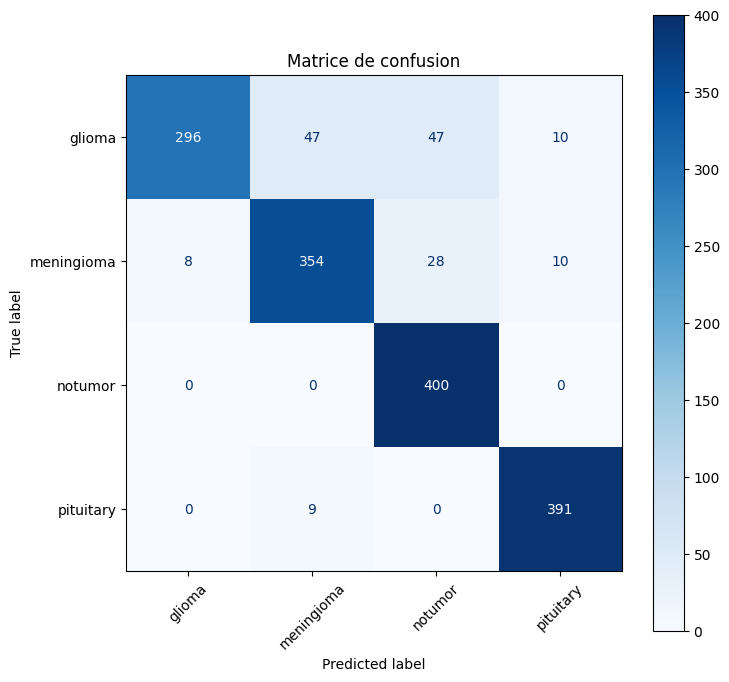

              precision    recall  f1-score   support

      glioma     0.9737    0.7400    0.8409       400
  meningioma     0.8634    0.8850    0.8741       400
     notumor     0.8421    1.0000    0.9143       400
   pituitary     0.9513    0.9775    0.9642       400

    accuracy                         0.9006      1600
   macro avg     0.9076    0.9006    0.8984      1600
weighted avg     0.9076    0.9006    0.8984      1600



In [37]:
from sklearn.metrics import (confusion_matrix, classification_report, ConfusionMatrixDisplay)
import numpy as np

test_generator.reset()

predictions = model.predict(test_generator)

y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

class_names = list(test_generator.class_indices.keys())

print("Classes :", class_names)

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title("Matrice de confusion")
plt.xticks(rotation=45)
plt.show()

# Rapport de classification
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

In [38]:
# Nous allons chercher à optimiser les hyperparametres


# Sauvegarder les courbes du modèle de référence
reference_history = {
    key: list(values)
    for key, values in history.history.items()
}

# Sauvegarder le modèle de référence
model.save('/content/cnn_reference.keras')

print("Modèle de référence sauvegardé.")


Modèle de référence sauvegardé.


In [39]:
import random
import os
import tensorflow as tf

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# Valeurs possibles des hyperparamètres
learning_rates = [0.001, 0.0003, 0.0001]
batch_sizes = [16, 32, 64]
base_filters_list = [16, 32, 64]
dropout_rates = [0.3, 0.5, 0.6]

# Générer toutes les combinaisons possibles
configurations = [
    (lr, batch, filters, dropout)
    for lr in learning_rates
    for batch in batch_sizes
    for filters in base_filters_list
    for dropout in dropout_rates
]

# Sélectionner 8 combinaisons différentes
selected_configs = random.sample(configurations, 8)

print("Nombre de configurations :", len(selected_configs))

for i, config in enumerate(selected_configs):
    print(f"Configuration {i+1} :", config)

Nombre de configurations : 8
Configuration 1 : (0.001, 32, 32, 0.6)
Configuration 2 : (0.001, 16, 32, 0.3)
Configuration 3 : (0.0003, 16, 64, 0.6)
Configuration 4 : (0.0003, 16, 32, 0.5)
Configuration 5 : (0.0003, 16, 16, 0.5)
Configuration 6 : (0.001, 32, 64, 0.6)
Configuration 7 : (0.001, 32, 32, 0.5)
Configuration 8 : (0.0001, 32, 64, 0.3)


In [40]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, BatchNormalization,
    Flatten, Dense, Dropout
)

def create_model(base_filters, dropout_rate, learning_rate):

    model = Sequential([
        Conv2D(base_filters, (3, 3),
               activation='relu', padding='same',
               input_shape=(128, 128, 1)),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(base_filters * 2, (3, 3),
               activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(base_filters * 4, (3, 3),
               activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(base_filters * 8, (3, 3),
               activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Flatten(),
        Dense(256, activation='relu'),
        Dropout(dropout_rate),
        Dense(4, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [41]:
# On test les différentes combinaisons pour trouver les meilleurs hyperparametres

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

results = []
histories = []

best_val_loss = float('inf')
best_config = None
best_model_path = None

os.makedirs('/content/optimized_models', exist_ok=True)

for i, config in enumerate(selected_configs):

    lr, batch_size, base_filters, dropout_rate = config

    print(f"\n========== ESSAI {i+1}/8 ==========")
    print("Learning rate :", lr)
    print("Batch size :", batch_size)
    print("Filtres de base :", base_filters)
    print("Dropout :", dropout_rate)

    # Recréer les générateurs avec le batch size choisi
    train_datagen_opt = ImageDataGenerator(
        rescale=1./255,
        validation_split=0.2
    )

    train_gen_opt = train_datagen_opt.flow_from_directory(
        train_dir,
        target_size=(128, 128),
        color_mode='grayscale',
        batch_size=batch_size,
        class_mode='categorical',
        subset='training',
        shuffle=True,
        seed=42
    )

    val_gen_opt = train_datagen_opt.flow_from_directory(
        train_dir,
        target_size=(128, 128),
        color_mode='grayscale',
        batch_size=batch_size,
        class_mode='categorical',
        subset='validation',
        shuffle=False,
        seed=42
    )

    # Construire le modèle
    tf.keras.backend.clear_session()

    current_model = create_model(
        base_filters,
        dropout_rate,
        lr
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )

    # Entraîner
    current_history = current_model.fit(
        train_gen_opt,
        validation_data=val_gen_opt,
        epochs=15,
        callbacks=[early_stop],
        verbose=1
    )

    # Meilleure loss de validation obtenue
    min_val_loss = min(current_history.history['val_loss'])

    # Accuracy de validation à la meilleure époque
    best_epoch = np.argmin(current_history.history['val_loss'])
    val_accuracy = current_history.history['val_accuracy'][best_epoch]

    results.append({
        'learning_rate': lr,
        'batch_size': batch_size,
        'base_filters': base_filters,
        'dropout': dropout_rate,
        'val_loss': min_val_loss,
        'val_accuracy': val_accuracy
    })

    histories.append(current_history.history)

    # Sauvegarder le meilleur modèle
    if min_val_loss < best_val_loss:

        best_val_loss = min_val_loss
        best_config = config

        best_model_path = (
            f'/content/optimized_models/best_trial_{i+1}.keras'
        )

        current_model.save(best_model_path)

        print("Nouveau meilleur modèle sauvegardé !")

    print("Meilleure validation loss de cet essai :", min_val_loss)

print("\nOPTIMISATION TERMINÉE")
print("Meilleure configuration :", best_config)
print("Meilleure validation loss :", best_val_loss)


========== ESSAI 1/8 ==========
Learning rate : 0.001
Batch size : 32
Filtres de base : 32
Dropout : 0.6
Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 137ms/step - accuracy: 0.6138 - loss: 1.6784 - val_accuracy: 0.2500 - val_loss: 20.5274
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 133ms/step - accuracy: 0.7154 - loss: 0.7518 - val_accuracy: 0.2714 - val_loss: 15.9708
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 130ms/step - accuracy: 0.7317 - loss: 0.7371 - val_accuracy: 0.4152 - val_loss: 2.1833
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - accuracy: 0.7636 - loss: 0.6038 - val_accuracy: 0.7536 - val_loss: 0.6578
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 128ms/step - accuracy: 0.7853 - loss: 0.5429 - val_accuracy: 0.7643 - val_loss: 0.5423
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 132ms/step - accuracy: 0.7971 - loss: 0.5247 - val_accuracy: 0.7554 - val_loss: 0.7891
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 130ms/step - accuracy: 0.8268 - loss: 0.4735 - val_accuracy: 0.8232 - val_loss: 0.4350
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 131ms/step - accuracy: 0.8426 - loss:

In [42]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='val_loss',
    ascending=True
)

display(results_df)



,learning_rate,batch_size,base_filters,dropout,val_loss,val_accuracy
3,0.0003,16,32,0.5,0.195857,0.938393
7,0.0001,32,64,0.3,0.196715,0.937500
4,0.0003,16,16,0.5,0.212199,0.922321
6,0.0010,32,32,0.5,0.243458,0.913393
1,0.0010,16,32,0.3,0.248741,0.904464
0,0.0010,32,32,0.6,0.435026,0.823214
2,0.0003,16,64,0.6,0.442728,0.823214
5,0.0010,32,64,0.6,0.504570,0.794643


In [43]:
# Meilleurs parametres trouvés
best_lr, best_batch, best_filters, best_dropout = best_config

print("Meilleurs hyperparamètres :")
print("Learning rate :", best_lr)
print("Batch size :", best_batch)
print("Filtres de base :", best_filters)
print("Dropout :", best_dropout)

Meilleurs hyperparamètres :
Learning rate : 0.0003
Batch size : 16
Filtres de base : 32
Dropout : 0.5


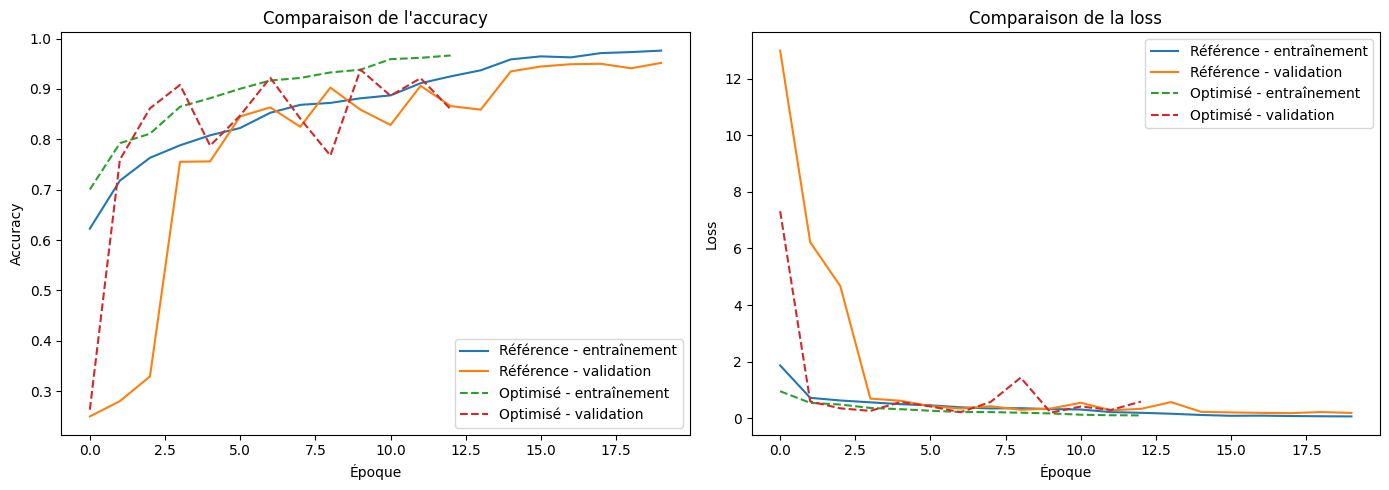

In [44]:
# Comparaison visuelle du modèle de référence et le meilleur

best_trial_index = min(
    range(len(histories)),
    key=lambda i: min(histories[i]['val_loss'])
)

optimized_history = histories[best_trial_index]

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    reference_history['accuracy'],
    label='Référence - entraînement'
)
plt.plot(
    reference_history['val_accuracy'],
    label='Référence - validation'
)

plt.plot(
    optimized_history['accuracy'],
    '--',
    label='Optimisé - entraînement'
)
plt.plot(
    optimized_history['val_accuracy'],
    '--',
    label='Optimisé - validation'
)

plt.title("Comparaison de l'accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    reference_history['loss'],
    label='Référence - entraînement'
)
plt.plot(
    reference_history['val_loss'],
    label='Référence - validation'
)

plt.plot(
    optimized_history['loss'],
    '--',
    label='Optimisé - entraînement'
)
plt.plot(
    optimized_history['val_loss'],
    '--',
    label='Optimisé - validation'
)

plt.title("Comparaison de la loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [45]:
best_model = tf.keras.models.load_model(best_model_path)

best_model.summary()

best_model.save('/content/best_brain_tumor_cnn.keras')

print("Meilleur modèle sauvegardé avec succès !")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,754,126 (52.47 MB)

 Trainable params: 4,584,388 (17.49 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 9,168,778 (34.98 MB)

Meilleur modèle sauvegardé avec succès !
